# Previsão de salários em vagas de TI — V02

Notebook reorganizado para execução local em Jupyter/VS Code, com dados em `data/ai_job_dataset.csv`, arquitetura única em PyTorch e extração de embeddings BERT em lotes. Por padrão, executa um subconjunto para facilitar testes em CPU; ajuste `MAX_ROWS = None` para usar todos os registros.

## 1. Configuração e reprodutibilidade

Execute as células em ordem. A primeira execução baixa `bert-base-uncased`; depois, os embeddings são reutilizados em `artifacts/` quando o texto e a configuração forem iguais.

In [1]:
from pathlib import Path
import hashlib
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
MODEL_NAME = "bert-base-uncased"
MAX_LEN = 96
BERT_BATCH_SIZE = 8  # reduza para 4 se faltar memória
TRAIN_BATCH_SIZE = 64
EPOCHS = 10
MAX_ROWS = 1000  # execução de demonstração; use None para todos os registros
CACHE_DIR = Path("artifacts/embeddings")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {DEVICE}; PyTorch: {torch.__version__}")
if DEVICE.type == "cpu":
    print("CPU detectada: mantenha MAX_ROWS baixo no primeiro teste. A extração BERT é a etapa mais custosa.")

C:\Users\Rafael\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu; PyTorch: 2.14.1+cpu
CPU detectada: mantenha MAX_ROWS baixo no primeiro teste. A extração BERT é a etapa mais custosa.


## 2. Carregamento do dataset

O caminho é resolvido a partir da pasta atual ou da pasta pai, para funcionar quando o notebook for aberto a partir de subpastas.

In [2]:
candidate_paths = [Path("data/ai_job_dataset.csv"), Path("../data/ai_job_dataset.csv")]
CSV_PATH = next((p.resolve() for p in candidate_paths if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError("Não encontrei data/ai_job_dataset.csv. Coloque o CSV na pasta data/ na raiz do projeto.")

start = time.perf_counter()
df = pd.read_csv(CSV_PATH)
print(f"CSV: {CSV_PATH}\nDimensões originais: {df.shape}\nLeitura: {time.perf_counter()-start:.2f}s")
display(df.head())
print("Colunas:", df.columns.tolist())

CSV: C:\Users\Rafael\OneDrive - UniCEUB\Documentos\Inteligência Artificial\data\ai_job_dataset.csv
Dimensões originais: (15000, 19)
Leitura: 0.07s


,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.9,Smart Analytics
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.2,TechCorp Inc
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.4,Autonomous Tech
3,AI00004,NLP Engineer,80215,USD,SE,FL,India,M,India,50,"Scala, SQL, Linux, Python",PhD,7,Consulting,2024-12-23,2025-02-24,1345,8.6,Future Systems
4,AI00005,AI Consultant,54624,EUR,EN,PT,France,S,Singapore,100,"MLOps, Java, Tableau, Python",Master,0,Media,2025-04-15,2025-06-23,1989,6.6,Advanced Robotics


Colunas: ['job_id', 'job_title', 'salary_usd', 'salary_currency', 'experience_level', 'employment_type', 'company_location', 'company_size', 'employee_residence', 'remote_ratio', 'required_skills', 'education_required', 'years_experience', 'industry', 'posting_date', 'application_deadline', 'job_description_length', 'benefits_score', 'company_name']


## 3. Validação e preparação

A variável-alvo é `salary_usd`; o texto combina `job_title` e `required_skills`, que são as colunas disponíveis no dataset usado pelo notebook original. O split ocorre antes de ajustar os transformadores, evitando vazamento de informação.

In [3]:
target = "salary_usd"
required = [target, "job_title", "required_skills"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Colunas necessárias ausentes: {missing}. Verifique se este é o dataset esperado.")

numeric_candidates = ["remote_ratio", "years_experience", "job_description_length", "benefits_score"]
categorical_candidates = ["experience_level", "employment_type", "company_location", "company_size", "employee_residence", "education_required", "industry", "salary_currency", "company_name"]
numeric_features = [c for c in numeric_candidates if c in df.columns]
categorical_features = [c for c in categorical_candidates if c in df.columns]

data = df.copy()
data[target] = pd.to_numeric(data[target], errors="coerce")
data = data.dropna(subset=[target]).copy()
data["text_input"] = (data["job_title"].fillna("").astype(str) + " [SEP] " + data["required_skills"].fillna("").astype(str)).str.strip()
data = data[data["text_input"].str.len() > 0].reset_index(drop=True)
if MAX_ROWS is not None and len(data) > MAX_ROWS:
    data = data.sample(n=MAX_ROWS, random_state=SEED).reset_index(drop=True)

if len(data) < 10:
    raise ValueError("Há poucos registros válidos para separar treino e validação.")

indices = np.arange(len(data))
train_idx, val_idx = train_test_split(indices, test_size=0.2, random_state=SEED)
train_df = data.iloc[train_idx].reset_index(drop=True)
val_df = data.iloc[val_idx].reset_index(drop=True)
y_train = train_df[target].to_numpy(dtype=np.float32)
y_val = val_df[target].to_numpy(dtype=np.float32)
print(f"Registros usados: {len(data)} | treino: {len(train_df)} | validação: {len(val_df)}")
print(f"Features numéricas: {numeric_features}\nFeatures categóricas: {categorical_features}")

Registros usados: 1000 | treino: 800 | validação: 200
Features numéricas: ['remote_ratio', 'years_experience', 'job_description_length', 'benefits_score']
Features categóricas: ['experience_level', 'employment_type', 'company_location', 'company_size', 'employee_residence', 'education_required', 'industry', 'salary_currency', 'company_name']


## 4. Pré-processamento das variáveis estruturadas

O transformador é ajustado somente no treino e reutilizado na validação. `OrdinalEncoder` mantém a matriz compacta para não expandir colunas de alta cardinalidade, como nome de empresa e cargo.

In [4]:
transformers = []
if numeric_features:
    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    transformers.append(("num", numeric_pipeline, numeric_features))
if categorical_features:
    categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))])
    transformers.append(("cat", categorical_pipeline, categorical_features))
if not transformers:
    raise ValueError("Nenhuma feature estruturada disponível.")

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
X_struct_train = preprocessor.fit_transform(train_df).astype(np.float32)
X_struct_val = preprocessor.transform(val_df).astype(np.float32)
print("Dimensões estruturadas:", X_struct_train.shape, X_struct_val.shape)

Dimensões estruturadas: (800, 13) (200, 13)


## 5. Extração e cache de embeddings BERT

Como o BERT fica congelado, não há necessidade de recalcular embeddings em cada época. `torch.inference_mode()` reduz memória e custo de autograd; o cache é invalidado automaticamente se o conjunto de textos ou os parâmetros de tokenização mudarem.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
bert.eval()
for parameter in bert.parameters():
    parameter.requires_grad = False

def cache_key(texts):
    payload = json.dumps({"model": MODEL_NAME, "max_len": MAX_LEN, "texts": list(texts)}, ensure_ascii=False).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()[:20]

def get_bert_embeddings(texts, split_name):
    key = cache_key(texts)
    cache_path = CACHE_DIR / f"{split_name}_{key}.npy"
    if cache_path.exists():
        print(f"Cache encontrado: {cache_path}")
        return np.load(cache_path).astype(np.float32)
    outputs = []
    start = time.perf_counter()
    with torch.inference_mode():
        for start_idx in range(0, len(texts), BERT_BATCH_SIZE):
            batch_texts = list(texts[start_idx:start_idx + BERT_BATCH_SIZE])
            tokens = tokenizer(batch_texts, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
            tokens = {k: v.to(DEVICE) for k, v in tokens.items()}
            result = bert(**tokens)
            cls_embedding = result.last_hidden_state[:, 0, :]
            outputs.append(cls_embedding.cpu().numpy().astype(np.float32))
    embeddings = np.concatenate(outputs, axis=0)
    np.save(cache_path, embeddings)
    print(f"Embeddings {split_name}: {embeddings.shape}; tempo: {time.perf_counter()-start:.1f}s; cache salvo.")
    return embeddings

X_text_train = get_bert_embeddings(train_df["text_input"].tolist(), "train")
X_text_val = get_bert_embeddings(val_df["text_input"].tolist(), "validation")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 562.57it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embeddings train: (800, 768); tempo: 20.6s; cache salvo.
Embeddings validation: (200, 768); tempo: 4.9s; cache salvo.


## 6. Modelo híbrido BERT + variáveis estruturadas

O BERT atua como extrator congelado de características; a rede densa aprende a regressão a partir da concatenação dos embeddings com os dados tabulares.

In [6]:
X_train_all = np.concatenate([X_text_train, X_struct_train], axis=1).astype(np.float32)
X_val_all = np.concatenate([X_text_val, X_struct_val], axis=1).astype(np.float32)

class SalaryRegressor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.network(x).squeeze(1)

model = SalaryRegressor(X_train_all.shape[1]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()
train_dataset = TensorDataset(torch.from_numpy(X_train_all), torch.from_numpy(y_train))
train_loader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True)
X_val_tensor = torch.from_numpy(X_val_all).to(DEVICE)
y_val_tensor = torch.from_numpy(y_val).to(DEVICE)

history = {"train_mse": [], "val_mse": []}
for epoch in range(EPOCHS):
    model.train()
    losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        predictions = model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    model.eval()
    with torch.inference_mode():
        val_loss = criterion(model(X_val_tensor), y_val_tensor).item()
    history["train_mse"].append(float(np.mean(losses)))
    history["val_mse"].append(val_loss)
    print(f"Época {epoch+1:02d}/{EPOCHS} | MSE treino: {history['train_mse'][-1]:,.2f} | MSE validação: {val_loss:,.2f}")

Época 01/10 | MSE treino: 17,227,779,387.08 | MSE validação: 16,788,502,528.00
Época 02/10 | MSE treino: 17,324,720,994.46 | MSE validação: 16,776,515,584.00
Época 03/10 | MSE treino: 17,206,821,021.54 | MSE validação: 16,745,601,024.00
Época 04/10 | MSE treino: 17,264,870,793.85 | MSE validação: 16,680,741,888.00
Época 05/10 | MSE treino: 16,808,905,649.23 | MSE validação: 16,563,545,088.00
Época 06/10 | MSE treino: 17,139,891,593.85 | MSE validação: 16,372,793,344.00
Época 07/10 | MSE treino: 16,605,183,133.54 | MSE validação: 16,083,947,520.00
Época 08/10 | MSE treino: 16,194,532,115.69 | MSE validação: 15,679,764,480.00
Época 09/10 | MSE treino: 15,864,801,201.23 | MSE validação: 15,142,593,536.00
Época 10/10 | MSE treino: 15,297,775,143.38 | MSE validação: 14,454,878,208.00


## 7. Avaliação

As métricas são calculadas na partição de validação, que não foi usada para ajustar o pré-processador nem treinar a rede. O modo demonstração (1.000 registros por padrão) não deve ser confundido com o resultado final do experimento completo.

,Métrica,Valor
0,MAE,1.039307e+05
1,MSE,1.445488e+10
2,RMSE,1.202284e+05
3,R²,-2.948627e+00


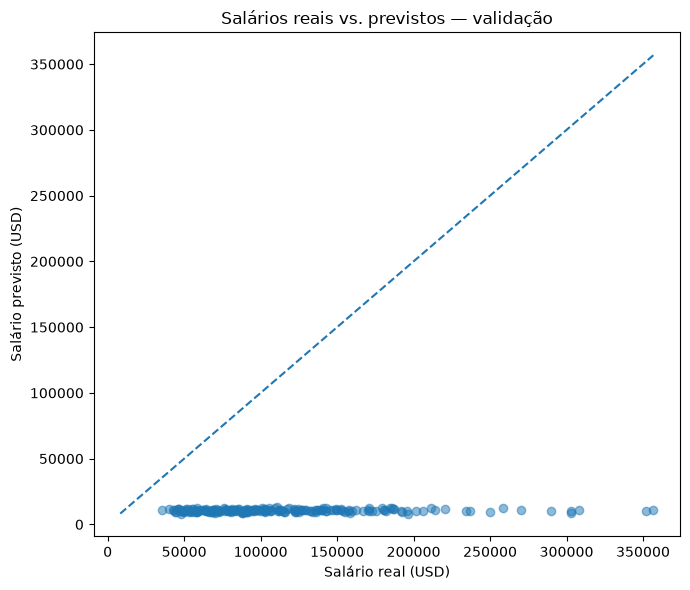

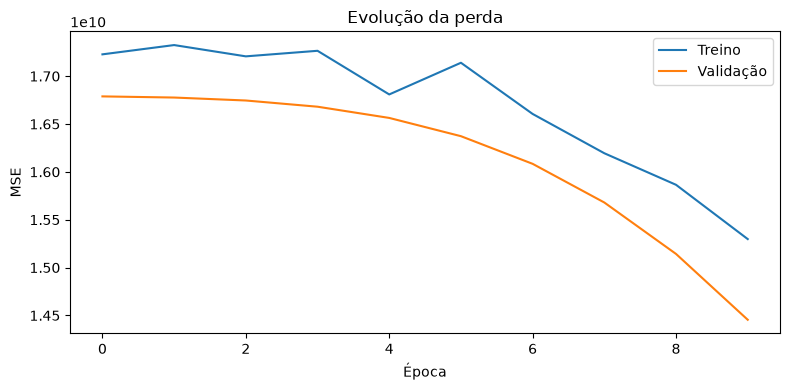

In [7]:
model.eval()
with torch.inference_mode():
    y_pred = model(X_val_tensor).cpu().numpy()

mae = mean_absolute_error(y_val, y_pred)
mse = mean_squared_error(y_val, y_pred)
rmse = float(np.sqrt(mse))
r2 = r2_score(y_val, y_pred)
metrics = pd.DataFrame({"Métrica": ["MAE", "MSE", "RMSE", "R²"], "Valor": [mae, mse, rmse, r2]})
display(metrics)

plt.figure(figsize=(7, 6))
plt.scatter(y_val, y_pred, alpha=0.5)
lower = min(float(np.min(y_val)), float(np.min(y_pred)))
upper = max(float(np.max(y_val)), float(np.max(y_pred)))
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Salário real (USD)")
plt.ylabel("Salário previsto (USD)")
plt.title("Salários reais vs. previstos — validação")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history["train_mse"], label="Treino")
plt.plot(history["val_mse"], label="Validação")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Evolução da perda")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Salvamento dos artefatos

O modelo salvo aqui é a rede densa treinada sobre embeddings BERT e features estruturadas. Para realizar inferências futuras, também será necessário salvar o pré-processador e manter a configuração/tokenizador correspondente. Este bloco salva os pesos e o pré-processador via `joblib`.

In [8]:
import joblib
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
torch.save({"state_dict": model.state_dict(), "input_dim": X_train_all.shape[1], "model_name": MODEL_NAME, "max_len": MAX_LEN}, MODEL_DIR / "salary_regressor_v02.pt")
joblib.dump(preprocessor, MODEL_DIR / "structured_preprocessor_v02.joblib")
metrics.to_csv(MODEL_DIR / "validation_metrics_v02.csv", index=False)
print("Artefatos salvos em:", MODEL_DIR.resolve())

Artefatos salvos em: C:\Users\Rafael\OneDrive - UniCEUB\Documentos\Inteligência Artificial\models


## 9. Limitações e próximos experimentos

- Reexecute com `MAX_ROWS = None` para o experimento completo, se a memória e o tempo permitirem.
- Compare com um baseline simples (por exemplo, `DummyRegressor` e `RandomForestRegressor`) para verificar se BERT agrega valor.
- Não balanceie regiões antes da divisão treino/validação: isso pode alterar a distribuição do alvo e introduzir duplicatas entre partições.
- A feature `company_name` e outras variáveis categóricas podem ter cardinalidade alta; o `OrdinalEncoder` evita uma matriz enorme, mas cria códigos sem significado ordinal real. Compare com alternativas adequadas.
- O dataset contém snapshots de vagas; este notebook não modela diretamente uma série temporal. Para afirmar evolução salarial ao longo do tempo, será necessário analisar a variável de ano/data e avaliar por período.
- Resultados finais devem ser registrados após executar o pipeline completo em ambiente limpo; os resultados de demonstração não são uma avaliação final.